**Formative 1 Group 3**
---


**BSE - African Leadership University**

**Machine Learning Pipeline**

**Formative 1 -  Building a Pipeline for Time Series Data**

# Beijing PM2.5: Understanding and Forecasting Air Pollution


### What we are investigating
We want to understand how PM2.5 (Particulate Matters) pollution changed in Beijing from 2010 to 2014 and whether earlier readings can help us predict the next hour. The dataset also includes weather observations, so we can check whether they add useful information. PM2.5 is the concentration of fine particles in the air, measured in µg/m³.

## Dataset Information

This hourly data set contains the PM2.5 data of US Embassy in Beijing. Meanwhile, meteorological data from Beijing Capital International Airport are also included.

The data's time period is between Jan 1st, 2010 to Dec 31st, 2014. Missing data are denoted as "NA".

**Dataset Columns**

No: row number

year: year of data in this row

month: month of data in this row

day: day of data in this row

hour: hour of data in this row

pm2.5: PM2.5 concentration (ug/m^3)

DEWP: Dew Point (â„ƒ)

TEMP: Temperature (â„ƒ)

PRES: Pressure (hPa)

cbwd: Combined wind direction

Iws: Cumulated wind speed (m/s)

Is: Cumulated hours of snow

Ir: Cumulated hours of rain

*Credits to:* Chen, S. (2015). Beijing PM2.5 [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5JS49.

## A. Exploratory Data Analysis (EDA)

I will start by loading the file as provided. Before changing anything, I want to see the columns, data types and a few records.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/content/PRSA_data_2010.1.1-2014.12.31.csv")
df.head()

,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   No      43824 non-null  int64  
 1   year    43824 non-null  int64  
 2   month   43824 non-null  int64  
 3   day     43824 non-null  int64  
 4   hour    43824 non-null  int64  
 5   pm2.5   41757 non-null  float64
 6   DEWP    43824 non-null  int64  
 7   TEMP    43824 non-null  float64
 8   PRES    43824 non-null  float64
 9   cbwd    43824 non-null  object 
 10  Iws     43824 non-null  float64
 11  Is      43824 non-null  int64  
 12  Ir      43824 non-null  int64  
dtypes: float64(4), int64(8), object(1)
memory usage: 4.3+ MB


In [ ]:
df.shape, df.columns.tolist()

((43824, 13),
 ['No',
  'year',
  'month',
  'day',
  'hour',
  'pm2.5',
  'DEWP',
  'TEMP',
  'PRES',
  'cbwd',
  'Iws',
  'Is',
  'Ir'])

The date is spread across four columns, ```year```, ```month```, ```day```, and ```hour```. I will check missing values first, then put these columns together as one timestamp so that the hours stay in the right order.

In [ ]:
df.isna().sum().sort_values(ascending=False)

,0
pm2.5,2067
year,0
month,0
day,0
No,0
hour,0
DEWP,0
TEMP,0
PRES,0
cbwd,0


Only one column ```pm2.5``` that is the target value has missing vaues

In [ ]:
df[["year", "month", "day", "hour"]].head()

,year,month,day,hour
0,2010,1,1,0
1,2010,1,1,1
2,2010,1,1,2
3,2010,1,1,3
4,2010,1,1,4


In [ ]:
df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.sort_values("datetime").set_index("datetime")
df.head()

,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
datetime,,,,,,,,,,,,,
2010-01-01 00:00:00,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
2010-01-01 01:00:00,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2010-01-01 02:00:00,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
2010-01-01 03:00:00,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
2010-01-01 04:00:00,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


### Time range and frequency
Based on the dataset source description about the dataset, one row should represent one hour. I will verify that the records really follow this pattern, rather than relying only on the dataset description.

In [ ]:
print("First reading:", df.index.min())
print("Last reading:", df.index.max())
print("Number of rows:", len(df))
print("Time intervals:", df.index.to_series().diff().value_counts().head())
print("Duplicate hours:", df.index.duplicated().sum())
print("Missing hours:", len(pd.date_range(df.index.min(), df.index.max(), freq="h").difference(df.index)))

First reading: 2010-01-01 00:00:00
Last reading: 2014-12-31 23:00:00
Number of rows: 43824
Time intervals: datetime
0 days 01:00:00    43823
Name: count, dtype: int64
Duplicate hours: 0
Missing hours: 0


The timestamp is now a proper datetime index. I will take a closer look at one month to check that the hourly records are easy to follow.

In [ ]:
df.loc["2012-01-01":"2012-01-02", ["pm2.5", "TEMP", "PRES", "Iws"]].head(12)

,pm2.5,TEMP,PRES,Iws
datetime,,,,
2012-01-01 00:00:00,275.0,-8.0,1030.0,0.89
2012-01-01 01:00:00,303.0,-10.0,1031.0,1.79
2012-01-01 02:00:00,215.0,-9.0,1032.0,3.58
2012-01-01 03:00:00,222.0,-9.0,1033.0,6.71
2012-01-01 04:00:00,85.0,-4.0,1033.0,4.92
2012-01-01 05:00:00,38.0,-4.0,1034.0,10.73
2012-01-01 06:00:00,23.0,-4.0,1034.0,14.75
2012-01-01 07:00:00,19.0,-5.0,1035.0,17.88
2012-01-01 08:00:00,14.0,-4.0,1035.0,21.90


## Handling the Missing Values
A missing PM2.5 value means the pollution reading was not recorded. It does **not** mean that pollution was zero. I will examine how large the missing gaps are before deciding what to do.

In [ ]:
missing = df["pm2.5"].isna()
print("Missing PM2.5:", missing.sum())
print("Missing share: {:.2f}%".format(missing.mean() * 100))
print("Other missing values:", df.drop(columns="pm2.5").isna().sum().sum())
print("Missing readings by year:")
print(missing.groupby(df.index.year).sum())

Missing PM2.5: 2067
Missing share: 4.72%
Other missing values: 0
Missing readings by year:
datetime
2010    669
2011    728
2012    489
2013     82
2014     99
Name: pm2.5, dtype: int64


In [ ]:
gaps = missing.ne(missing.shift()).cumsum()
gap_sizes = missing.groupby(gaps).sum()
print("Longest missing run (hours):", gap_sizes.max())
print("Missing runs longer than 3 hours:", (gap_sizes > 3).sum())

Longest missing run (hours): 155
Missing runs longer than 3 hours: 71


## Key Decisions

Some short gaps can be filled from the most recent available reading, but long gaps should not be invented. I will only carry a reading forward for up to three hours **when building historical model inputs**. The original target stays unchanged, so we never train or evaluate against a made-up PM2.5 reading.

In [ ]:
df["pm_history"] = df["pm2.5"].ffill(limit=3)
print("Missing historical inputs after limited filling:", df["pm_history"].isna().sum())
print("Original target still missing:", df["pm2.5"].isna().sum())

Missing historical inputs after limited filling: 1681
Original target still missing: 2067


Next I will look at summary statistics and distributions. I want to see typical pollution values, whether extreme readings exist, and how the weather variables are spread.

In [ ]:
numeric = ["pm2.5", "DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]
df[numeric].describe().round(2)

,pm2.5,DEWP,TEMP,PRES,Iws,Is,Ir
count,41757.00,43824.00,43824.00,43824.00,43824.00,43824.00,43824.00
mean,98.61,1.82,12.45,1016.45,23.89,0.05,0.19
std,92.05,14.43,12.20,10.27,50.01,0.76,1.42
min,0.00,-40.00,-19.00,991.00,0.45,0.00,0.00
25%,29.00,-10.00,2.00,1008.00,1.79,0.00,0.00
50%,72.00,2.00,14.00,1016.00,5.37,0.00,0.00
75%,137.00,15.00,23.00,1025.00,21.91,0.00,0.00
max,994.00,28.00,42.00,1046.00,585.60,27.00,36.00


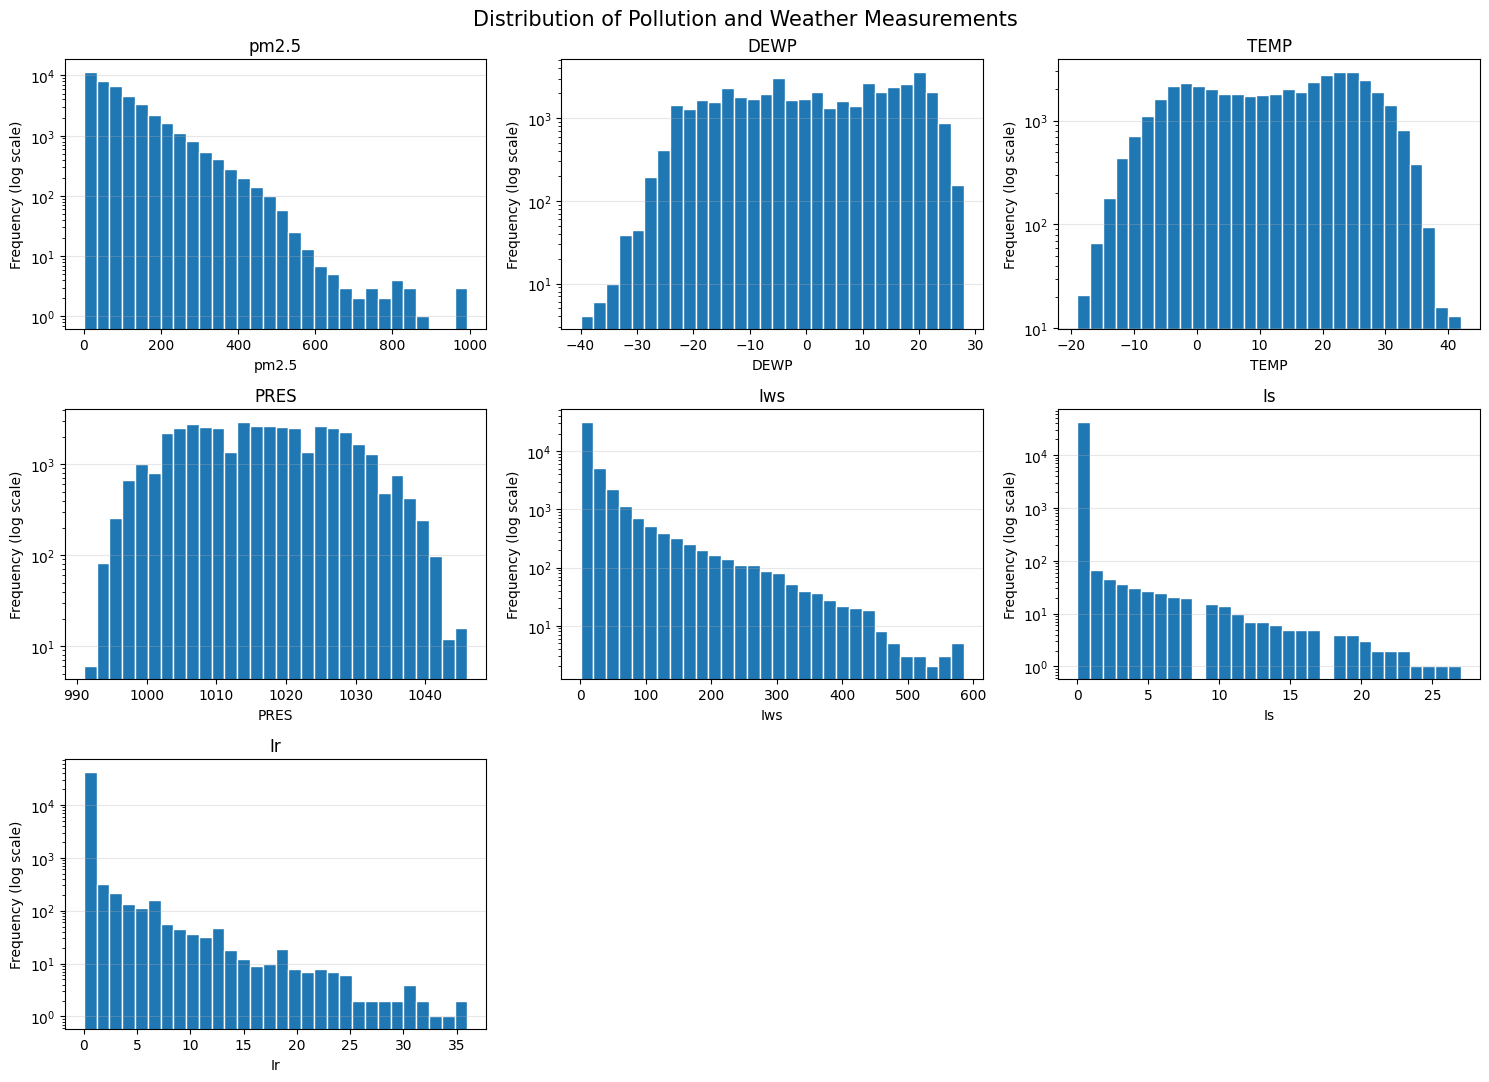

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(numeric):
    axes[i].hist(df[col].dropna(), bins=30, edgecolor="white")
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency (log scale)")
    axes[i].set_yscale("log")
    axes[i].grid(axis="y", alpha=0.3)

for ax in axes[len(numeric):]:
    ax.remove()

plt.suptitle("Distribution of Pollution and Weather Measurements", fontsize=15)
plt.tight_layout()
plt.show()

**What to notice:** The mean PM2.5 concentration (98.61) is higher than the median (72), indicating a right-skewed distribution. The histogram confirms this, with most observations concentrated at lower values and fewer readings extending towards 994. These high readings may represent important pollution events, so they should be investigated rather than automatically removed during preprocessing.

## B. Analytical Questions
Each question below includes a plot and a short interpretation based on a value calculated from the data.

### Question 1: Does PM2.5 have an increasing/decreasing trend between 2010 and 2014?
We will use monthly averages so that hourly fluctuations do not hide the overall direction.

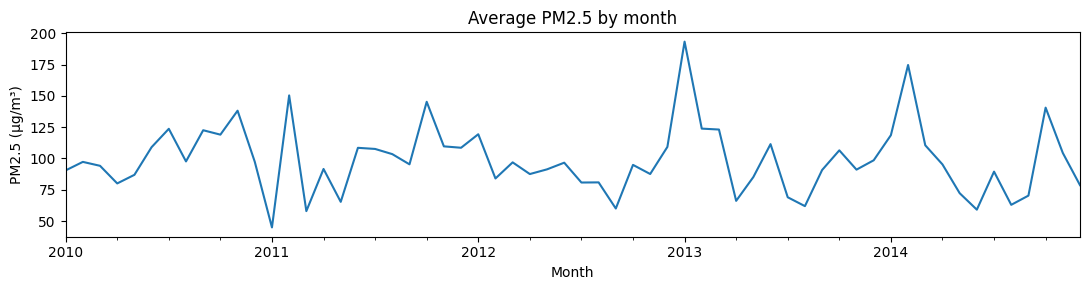

Average in 2010: 104.0
Average in 2014: 97.7


In [ ]:
monthly = df["pm2.5"].resample("MS").mean()
monthly.plot(figsize=(11, 3), title="Average PM2.5 by month")
plt.ylabel("PM2.5 (µg/m³)")
plt.xlabel("Month")
plt.tight_layout()
plt.show()
print("Average in 2010:", round(df.loc["2010", "pm2.5"].mean(), 1))
print("Average in 2014:", round(df.loc["2014", "pm2.5"].mean(), 1))

**Interpretation:** The average PM2.5 concentration decreased slightly from 104.0 µg/m³ in 2010 to 97.7 µg/m³ in 2014. However, the monthly averages fluctuate considerably, with several noticeable peaks throughout the period. This suggests a slight overall decrease between the first and last years, rather than a consistent downward trend.

### Question 2: Is there a relationship between weather conditions and PM2.5 concentrations?
We explore how temperature, dew point, atmospheric pressure, and wind speed relate to PM2.5 concentrations.

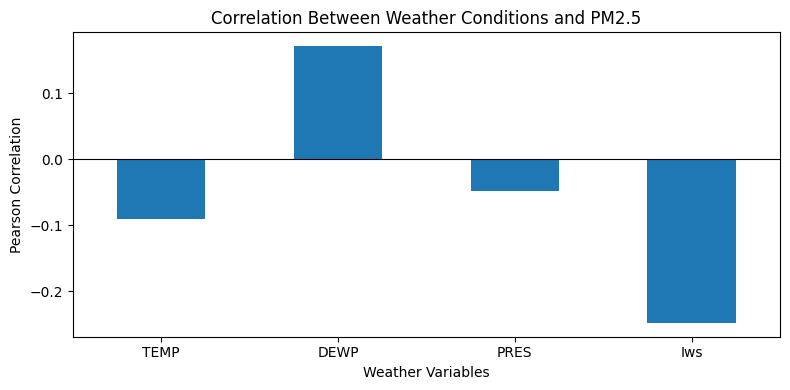

TEMP   -0.091
DEWP    0.171
PRES   -0.047
Iws    -0.248
Name: pm2.5, dtype: float64


In [ ]:
weather = ["TEMP", "DEWP", "PRES", "Iws"]

correlation = df[["pm2.5"] + weather].corr()["pm2.5"].drop("pm2.5")

correlation.plot(kind="bar", figsize=(8, 4))

plt.title("Correlation Between Weather Conditions and PM2.5")
plt.xlabel("Weather Variables")
plt.ylabel("Pearson Correlation")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(correlation.round(3))

**Interpretation:** Wind speed has the strongest negative correlation with PM2.5 (-0.248), suggesting that higher wind speeds are associated with lower pollution levels. Dew point shows a weak positive correlation (0.171), while temperature (-0.091) and atmospheric pressure (-0.047) have very weak negative correlations. Overall, the weather variables show relatively weak linear relationships with PM2.5.

### Question 3 : Are there lag effects? (Does pollution from earlier hours relate to pollution now?)
We examine whether current PM2.5 concentrations are related to pollution levels recorded in previous hours.

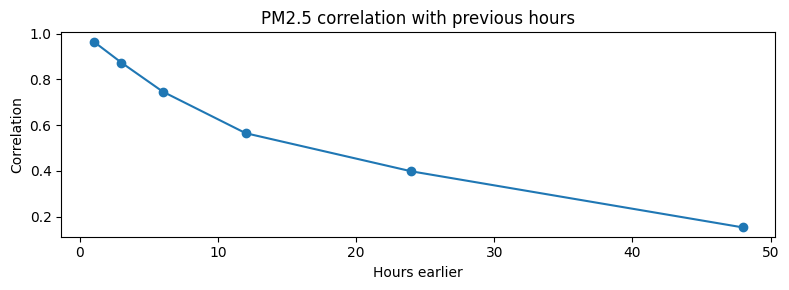

1     0.965
3     0.874
6     0.747
12    0.565
24    0.398
48    0.153
dtype: float64


In [ ]:
lags = [1, 3, 6, 12, 24, 48]
lag_corr = pd.Series({h: df["pm2.5"].corr(df["pm2.5"].shift(h)) for h in lags})
lag_corr.plot(marker="o", figsize=(8, 3), title="PM2.5 correlation with previous hours")
plt.xlabel("Hours earlier")
plt.ylabel("Correlation")
plt.tight_layout()
plt.show()
print(lag_corr.round(3))

**Interpretation:** PM2.5 shows strong lag effects, especially over shorter time gaps. The correlation is very high at 1 hour earlier (0.965) and remains fairly strong at 3 hours (0.874) and 6 hours (0.747), showing that recent pollution levels are closely related to current levels. The relationship becomes weaker as the time gap increases, dropping to 0.398 at 24 hours and 0.153 at 48 hours.

### Question 4: What do moving averages reveal about changes in PM2.5 concentrations?

Here we use 24-hour and 7-day moving averages to examine short-term fluctuations and longer-term pollution patterns.

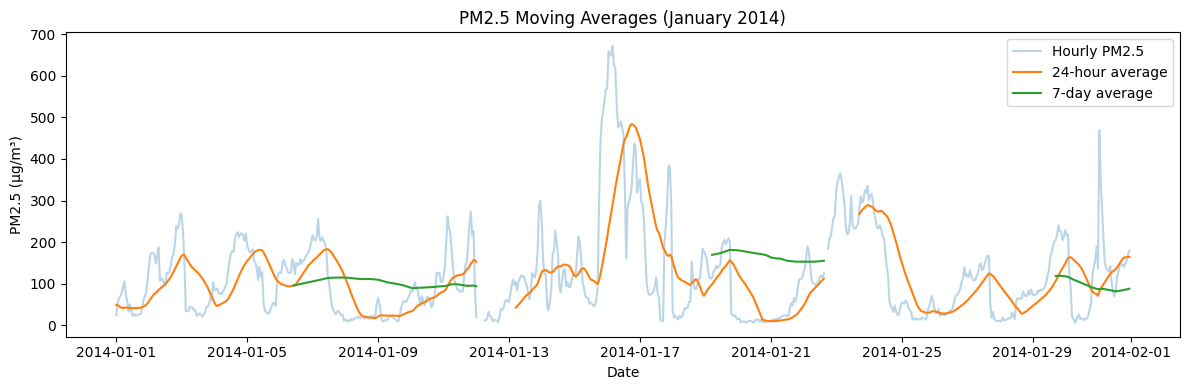

In [ ]:
daily_avg = df["pm2.5"].rolling(24).mean()
weekly_avg = df["pm2.5"].rolling(168).mean()

plt.figure(figsize=(12, 4))
plt.plot(df["pm2.5"].loc["2014-01"], alpha=0.3, label="Hourly PM2.5")
plt.plot(daily_avg.loc["2014-01"], label="24-hour average")
plt.plot(weekly_avg.loc["2014-01"], label="7-day average")

plt.title("PM2.5 Moving Averages (January 2014)")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:** The hourly PM2.5 readings fluctuate considerably, with a sharp peak of approximately 670 µg/m³ around January 16. The 24-hour moving average smooths these fluctuations but still captures major pollution spikes, while the 7-day moving average remains more stable, showing the broader pollution pattern. This suggests that PM2.5 experiences sudden short-term increases alongside more gradual changes over time.

###Question 5: How do PM2.5 concentrations vary across different months of the year?

Comparing monthly pollution levels to investigate whether certain periods of the year consistently experience higher concentrations.

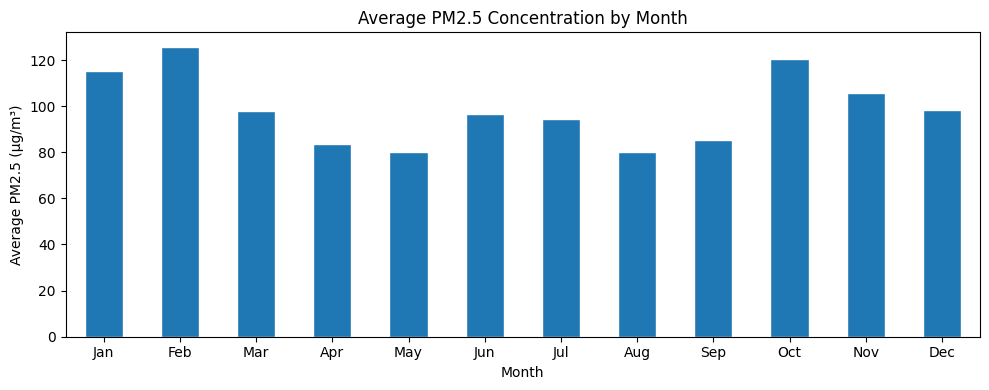

Highest average month: 2 | 125.7
Lowest average month: 8 | 80.0


In [ ]:
by_month = df.groupby(df.index.month)["pm2.5"].mean()

by_month.plot(kind="bar", figsize=(10, 4), edgecolor="white")

plt.title("Average PM2.5 Concentration by Month")
plt.xlabel("Month")
plt.ylabel("Average PM2.5 (µg/m³)")
plt.xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                       "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], rotation=0)
plt.tight_layout()
plt.show()

print("Highest average month:", by_month.idxmax(), "|", round(by_month.max(), 1))
print("Lowest average month:", by_month.idxmin(), "|", round(by_month.min(), 1))

**Interpretation:** PM2.5 concentrations vary across the months, showing a seasonal pattern. February has the highest average concentration (approximately 125 µg/m³), followed by October (120 µg/m³), while May and August have the lowest averages (around 80 µg/m³). This suggests that pollution levels tend to be higher in certain months, although the pattern may differ between years.

## C. Training a model (Forecasting the next hour)
For the model, I will predict PM2.5 at hour *t* using information available by hour *t − 1*. Calendar features can describe the hour we are predicting, but the pollution and weather inputs must come from earlier observations.

### Preparing model features
I will keep the original daily and hourly calendar information as useful features. The row number `No` is only an identifier, so it will not be used to forecast pollution.

In [ ]:
df["pm_lag_1"] = df["pm_history"].shift(1)
df["pm_lag_6"] = df["pm_history"].shift(6)
df["pm_lag_24"] = df["pm_history"].shift(24)
df["pm_avg_24"] = df["pm_history"].shift(1).rolling(24, min_periods=24).mean()
df["pm_avg_168"] = df["pm_history"].shift(1).rolling(168, min_periods=168).mean()
for name in weather:
    df[name + "_previous"] = df[name].shift(1)
df["hour_of_day"] = df.index.hour
df["month_of_year"] = df.index.month
df["day_of_week"] = df.index.dayofweek
df[["pm2.5", "pm_lag_1", "pm_lag_24", "pm_avg_24"]]

,pm2.5,pm_lag_1,pm_lag_24,pm_avg_24
datetime,,,,
2010-01-01 00:00:00,NaN,NaN,NaN,NaN
2010-01-01 01:00:00,NaN,NaN,NaN,NaN
2010-01-01 02:00:00,NaN,NaN,NaN,NaN
2010-01-01 03:00:00,NaN,NaN,NaN,NaN
2010-01-01 04:00:00,NaN,NaN,NaN,NaN
...,...,...,...,...
2014-12-31 19:00:00,8.0,10.0,35.0,12.416667
2014-12-31 20:00:00,10.0,8.0,26.0,11.291667
2014-12-31 21:00:00,10.0,10.0,20.0,10.625000


### Keeping training and testing in time order
I will train on earlier years, use 2013 for model selection and reserve 2014 for the final comparison. Rows without an actual PM2.5 target or the needed history are excluded from modelling only. The original measurements remain available for the database tasks.

In [ ]:
history_features = ["pm_lag_1", "pm_lag_6", "pm_lag_24", "pm_avg_24", "pm_avg_168"]
calendar_features = ["hour_of_day", "month_of_year", "day_of_week"]
weather_features = [name + "_previous" for name in weather]
all_features = history_features + calendar_features + weather_features
model_data = df.dropna(subset=["pm2.5"] + all_features).copy()
train = model_data.loc[:"2012-12-31"]
valid = model_data.loc["2013"]
test = model_data.loc["2014"]
print("Train:", len(train), "Validation:", len(valid), "Test:", len(test))

Train: 18869 Validation: 7884 Test: 7352


### Comparing experiments
I will start with a simple baseline: predict that the next hour will be the same as the previous hour. Then I will try Ridge regression, which lets us tune a regularization value (`alpha`). One version uses historical pollution and calendar features; another also includes weather from the previous hour.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
import joblib

def scores(actual, predicted):
    return round(mean_absolute_error(actual, predicted), 2), round(np.sqrt(mean_squared_error(actual, predicted)), 2)

def fit_ridge(columns, alpha, training):
    fitted = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    fitted.fit(training[columns], training["pm2.5"])
    return fitted

In [ ]:
experiments = []
experiments.append({"Experiment": "Previous hour baseline", "Features": "PM2.5 lag 1", "Alpha": "–",
                    "MAE": scores(valid["pm2.5"], valid["pm_lag_1"])[0],
                    "RMSE": scores(valid["pm2.5"], valid["pm_lag_1"])[1]})

settings = [("History + calendar", history_features + calendar_features),
            ("History + calendar + weather", all_features)]
for label, columns in settings:
    for alpha in [0.1, 1, 10, 100]:
        model = fit_ridge(columns, alpha, train)
        prediction = model.predict(valid[columns])
        mae, rmse = scores(valid["pm2.5"], prediction)
        experiments.append({"Experiment": label, "Features": len(columns), "Alpha": alpha,
                            "MAE": mae, "RMSE": rmse})
results = pd.DataFrame(experiments).sort_values("RMSE")
results

,Experiment,Features,Alpha,MAE,RMSE
6,History + calendar + weather,12,1,13.81,25.25
7,History + calendar + weather,12,10,13.81,25.25
5,History + calendar + weather,12,0.1,13.80,25.25
1,History + calendar,8,0.1,13.89,25.30
2,History + calendar,8,1,13.89,25.30
3,History + calendar,8,10,13.90,25.30
8,History + calendar + weather,12,100,13.89,25.30
4,History + calendar,8,100,14.00,25.35
0,Previous hour baseline,PM2.5 lag 1,–,13.68,25.70


**How I will choose:** Lower MAE and RMSE mean smaller forecasting errors. The model and alpha with the lowest validation RMSE will be selected. The 2014 test set has not been used to make that decision.

### Final evaluation
Now I will refit the chosen configuration using the training and validation years, then check it once on the held-out 2014 data. I will also show the baseline so we can see whether the trained model actually helps.

In [ ]:
candidates = results[results["Experiment"] != "Previous hour baseline"]
best = candidates.iloc[0]
best_features = dict(settings)[best["Experiment"]]
final_train = pd.concat([train, valid])
final_model = fit_ridge(best_features, float(best["Alpha"]), final_train)
predicted = final_model.predict(test[best_features])
comparison = pd.DataFrame([
    {"Model": "Previous hour baseline", "MAE": scores(test["pm2.5"], test["pm_lag_1"])[0], "RMSE": scores(test["pm2.5"], test["pm_lag_1"])[1]},
    {"Model": "Tuned Ridge", "MAE": scores(test["pm2.5"], predicted)[0], "RMSE": scores(test["pm2.5"], predicted)[1]}
])
print("Selected experiment:", best["Experiment"], "| alpha:", best["Alpha"])
comparison

Selected experiment: History + calendar + weather | alpha: 1


,Model,MAE,RMSE
0,Previous hour baseline,11.55,21.13
1,Tuned Ridge,11.69,20.83


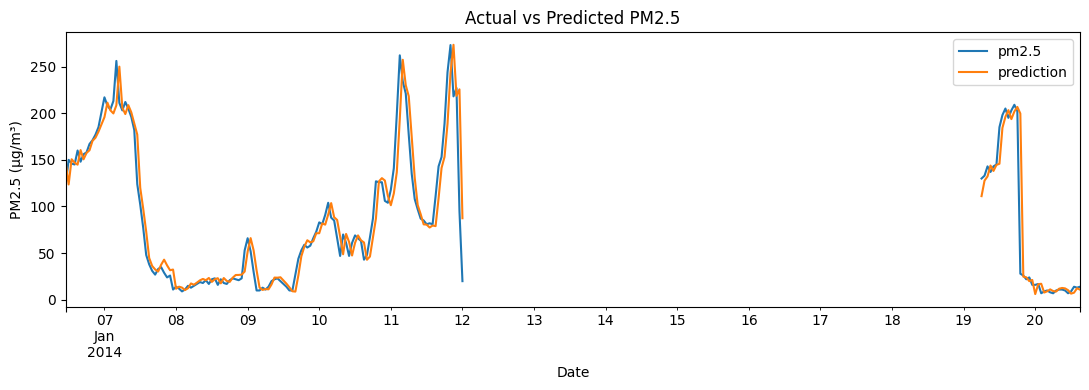

In [ ]:
view = test.iloc[:168].copy()
view["prediction"] = predicted[:len(view)]

view = view[["pm2.5", "prediction"]].asfreq("h")

view.plot(figsize=(11, 4), title="Actual vs Predicted PM2.5")

plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()

**Interpretation:** The Ridge Regression model closely follows the actual PM2.5 readings, capturing most fluctuations and pollution peaks. Small differences appear during sudden changes, but overall, the predictions visually align well with the observed values.

## Saving the model for the next tasks
Task 2 will store the timestamped pollution and weather measurements in MySQL and MongoDB. Task 3 will expose them through API endpoints. Task 4 will fetch enough recent hours to build the same lag and moving-average features before running the saved model.

In [ ]:
joblib.dump({"model": final_model, "features": best_features, "forecast": "next-hour PM2.5",
             "lag_hours": [1, 6, 24], "rolling_hours": [24, 168],
             "weather_from_previous_hour": True}, "/content/beijing_pm25_model.joblib")

# Export only the original observations for the database team.
original_columns = ["No", "year", "month", "day", "hour", "pm2.5", "DEWP", "TEMP", "PRES", "cbwd", "Iws", "Is", "Ir"]
df[original_columns].reset_index().to_csv("/content/beijing_records.csv", index=False)
print("Saved: beijing_pm25_model.joblib and beijing_records.csv")

Saved: beijing_pm25_model.joblib and beijing_records.csv
